# Clinical analysis

Transfer cached Wang and Meyer neighborhood embeddings to a frozen Wang state atlas, summarize patient state abundances, and recalculate pCR-model scores from saved neighborhood substitutions.

This CPU tutorial uses a subset of existing results: 2,000 embeddings from two patients per cohort, plus three saved Wang substitution cases. All inputs are bundled; no data or checkpoint download is needed. Calculations start from precomputed embeddings and post-substitution states, without rerunning the SOBER encoder.

Use Python 3.12 and install `requirements-tutorials.txt` with `constraints-tutorials.txt` from the repository root. Data and preparation are documented in [the example notes](../examples/data/README.md).

In [1]:
from pathlib import Path
import json
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sober/config.py").is_file())
sys.path.insert(0, str(ROOT))
from sober.checkpoint import file_sha256
from sober.clinical import assign_states, patient_abundance, update_state_counts, clinical_score

DATA = ROOT / "examples/clinical"
manifest = json.loads((DATA / "manifest.json").read_text())
for name, info in manifest["files"].items():
    assert file_sha256(DATA / name) == info["sha256"], f"Changed example file: {name}"
with np.load(DATA / "state_atlas.npz", allow_pickle=False) as payload:
    atlas = dict(payload)
with np.load(DATA / "transfer_embeddings.npz", allow_pickle=False) as payload:
    embeddings = payload["embeddings"]
    assert str(payload["neighborhood_embedding"]) == str(atlas["neighborhood_embedding"]) == "token_mean"
metadata = pd.read_csv(DATA / "transfer_metadata.csv", dtype={"cell_id": str})
assert len(embeddings) == len(metadata)
N_STATES = len(atlas["kmeans_centers"])
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})
display(metadata.groupby(["cohort", "patient"]).size().rename("cached neighborhoods").to_frame())

cached neighborhoods
cohort patient                              
Meyer  Meyer:B05.14713                   400
       Meyer:B05.34236                   400
Wang   Wang:NT001                        600
       Wang:NT002                        600

## Transfer the frozen neighborhood states

Use the saved scaler, PCA and nearest K-means centroids without refitting. The original centroid order is preserved, so C0–C14, including C4 and C6, retain their original Wang atlas IDs.

The 2,000 precomputed embeddings are a subset of the original cached exports: 1,200 Wang and 800 Meyer neighborhoods. We select the first two patient IDs in lexical order per cohort and retain all their cached neighborhoods. These 512-dimensional inputs are means of all contextual cell tokens, including the center. Meyer embeddings already include the recorded expression alignment to Wang.

C0–C14 are neighborhood states, not cell-type labels. Response associations come from the original Wang analysis, not from this small subset.

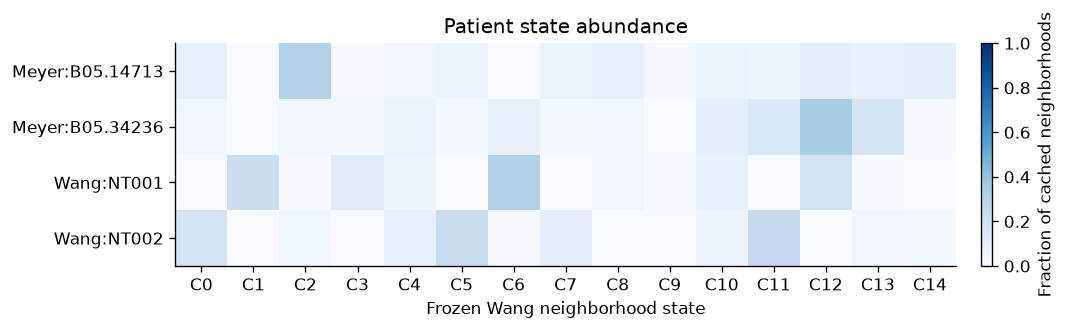

All state assignments match the saved research output.


In [2]:
states = assign_states(embeddings, atlas)
np.testing.assert_array_equal(states, metadata.saved_state.to_numpy())
assignments = metadata.assign(state=states)
abundance = patient_abundance(states, metadata.patient, N_STATES)
np.testing.assert_allclose(abundance.sum(axis=1), 1.)
fig, ax = plt.subplots(figsize=(9, 2.8))
im = ax.imshow(abundance.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set(xticks=range(N_STATES), xticklabels=[f"C{i}" for i in range(N_STATES)],
       yticks=range(len(abundance)), yticklabels=abundance.index,
       xlabel="Frozen Wang neighborhood state", title="Patient state abundance")
fig.colorbar(im, ax=ax, label="Fraction of cached neighborhoods", fraction=.03, pad=.03)
fig.tight_layout()
plt.show()
print("All state assignments match the saved research output.")

## Load the saved neighborhood-substitution cases

The research workflow kept a C4 tumor-centered recipient fixed, replaced its neighbors, re-encoded the input and reassigned its state. Three donor conditions are retained here: C6 responder context, a response-blind matched context, and a source-state non-responder matched context.

We use the first three patient IDs from saved chemotherapy-plus-immunotherapy (C&I) fold 1, repeat 0, including all attempted edits and their resulting states. The pathological complete response (pCR) head excludes these patients from fitting. It was reconstructed from the original patient feature table and checked against saved logits; the frozen atlas itself was learned from the source cohort without response labels.

In [3]:
cases = pd.read_csv(DATA / "clinical_cases.csv")
edits = pd.read_csv(DATA / "clinical_edits.csv")
expected = pd.read_csv(DATA / "clinical_expected.csv")
with np.load(DATA / "clinical_head.npz", allow_pickle=False) as payload:
    head = dict(payload)
assert set(cases.patient) <= set(head["held_out_patients"])
assert not set(cases.patient) & set(head["training_patients"])
assert list(head["feature_columns"]) == [f"cluster_{i}" for i in range(N_STATES)]
assert cases.fold.eq(int(head["fold"])).all()
assert not edits.duplicated(["patient", "condition", "recipient_row"]).any()
CONDITIONS = ["target_context", "biologically_matched_context", "source_state_matched_context"]
assert set(edits.condition) == set(CONDITIONS)
display(cases[["patient", "fold", "repeat", "n_neighborhoods"]])

,patient,fold,repeat,n_neighborhoods
0,NT003,1,0,600
1,NT087,1,0,600
2,NT089,1,0,600


## Update counts and recalculate model scores

For each edited neighborhood, subtract its original state and add its saved new state. Preserve the full patient's neighborhood total as the denominator, including unchanged neighborhoods. Apply the frozen fold-specific scaler and logistic head to the resulting 15-state abundance vector.

These are changes in a model's pCR score. They are not observed treatment responses or evidence that a patient would benefit from changing tissue context. Meyer phenotype labels are not used as pCR outcomes.

In [4]:
results, changed_counts = [], []
count_columns = [f"count_{i}" for i in range(N_STATES)]
for _, case in cases.iterrows():
    counts = case[count_columns].to_numpy(dtype=int)
    assert counts.sum() == case.n_neighborhoods
    original = clinical_score(counts, head)
    results.append({"patient": case.patient, "condition": "original", "n_edited": 0,
                    **original, "logit_change": 0., "probability_change": 0.})
    selected = edits.loc[edits.patient.eq(case.patient)]
    recipient_sets = [set(selected.loc[selected.condition.eq(c), "recipient_row"]) for c in CONDITIONS]
    assert all(ids == recipient_sets[0] for ids in recipient_sets)
    for condition in CONDITIONS:
        group = selected.loc[selected.condition.eq(condition)]
        updated = update_state_counts(counts, group.original_state, group.edited_state)
        assert updated.sum() == counts.sum()
        score = clinical_score(updated, head)
        results.append({"patient": case.patient, "condition": condition, "n_edited": len(group), **score,
                        "logit_change": score["logit"] - original["logit"],
                        "probability_change": score["probability"] - original["probability"]})
        changed_counts.append({"patient": case.patient, "condition": condition,
                               **dict(zip(count_columns, updated.tolist()))})
results = pd.DataFrame(results)
checked = results.merge(expected, on=["patient", "condition"], suffixes=("", "_saved"), validate="one_to_one")
assert len(checked) == len(results) == len(expected)
np.testing.assert_allclose(checked.logit, checked.logit_saved, atol=1e-5, rtol=0)
display(results[["patient", "condition", "n_edited", "logit", "logit_change"]].round(5))
print(f"Maximum difference from saved logits: {np.max(np.abs(checked.logit - checked.logit_saved)):.2g}")

,patient,condition,n_edited,logit,logit_change
0,NT003,original,0,0.81459,0.00000
1,NT003,target_context,1,0.83736,0.02277
2,NT003,biologically_matched_context,1,0.84825,0.03366
3,NT003,source_state_matched_context,1,0.83736,0.02277
4,NT087,original,0,2.12303,0.00000
5,NT087,target_context,20,2.68816,0.56513
6,NT087,biologically_matched_context,20,2.51266,0.38962
7,NT087,source_state_matched_context,20,2.32253,0.19950
8,NT089,original,0,1.25817,0.00000
9,NT089,target_context,6,1.38670,0.12853


Maximum difference from saved logits: 4.3e-07


## Compare target and control substitutions

Show every selected patient and control, including zero or negative changes. No effect-size or target-state-attainment filter is applied. The primary manuscript comparison is C6-responder replacement versus the response-blind matched control; the C4 non-responder control is an additional code-level comparison. This example keeps three patients and one repeat. Fig. S4D summarizes 53 patients after averaging five repeats within each patient.

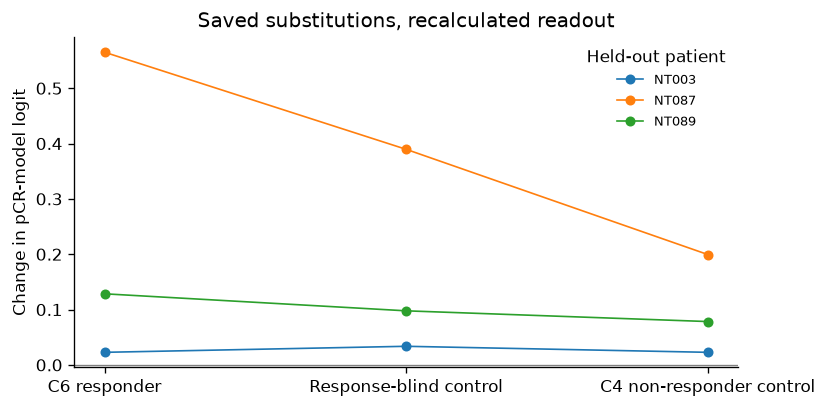

In [5]:
labels = ["C6 responder", "Response-blind control", "C4 non-responder control"]
clinical_fig, ax = plt.subplots(figsize=(7, 3.5))
for patient, group in results.loc[results.condition.ne("original")].groupby("patient"):
    values = group.set_index("condition").loc[CONDITIONS, "logit_change"]
    ax.plot(range(len(CONDITIONS)), values, "o-", ms=5, lw=1, label=patient)
ax.axhline(0, color="0.5", lw=.8)
ax.set(xticks=range(len(CONDITIONS)), xticklabels=labels,
       ylabel="Change in pCR-model logit", title="Saved substitutions, recalculated readout")
ax.legend(title="Held-out patient", frameon=False, fontsize=8)
clinical_fig.tight_layout()
plt.show()

## Save the outputs

To inspect a single case, filter `cases` and the corresponding `edits` and `expected` rows by patient before recalculating. Keep the full state counts for that patient.

In [6]:
OUT = ROOT / "outputs/clinical_perturbation"
OUT.mkdir(parents=True, exist_ok=True)
assignments.to_csv(OUT / "state_assignments.csv", index=False)
abundance.to_csv(OUT / "patient_abundance.csv")
results.to_csv(OUT / "clinical_scores.csv", index=False)
pd.DataFrame(changed_counts).to_csv(OUT / "edited_state_counts.csv", index=False)
fig.savefig(OUT / "state_abundance.png", dpi=180, bbox_inches="tight")
clinical_fig.savefig(OUT / "clinical_score_changes.png", dpi=180, bbox_inches="tight")
run = {"input_manifest_sha256": file_sha256(DATA / "manifest.json"),
       "source_code_sha256": file_sha256(ROOT / "sober/clinical.py"),
       "embedding_mode": "token_mean", "n_states": N_STATES, "clinical_patients": cases.patient.tolist(),
       "clinical_fold": int(head["fold"]), "clinical_repeat": 0,
       "input_scope": "Cached embeddings and post-substitution states; no encoder rerun or new tissue edits",
       "max_saved_logit_error": float(np.max(np.abs(checked.logit - checked.logit_saved))),
       "packages": {name: version(name) for name in ["numpy", "pandas", "scipy"]}}
(OUT / "evaluation.json").write_text(json.dumps(run, indent=2) + "\n")
print("Saved state assignments, patient abundances and model scores to outputs/clinical_perturbation")

Saved state assignments, patient abundances and model scores to outputs/clinical_perturbation
